In [2]:
# Action: import libraries
import pandas as pd # loading, cleaning and analysing the data
import numpy as np # numerical operations, if required
import requests # communicate with websites and web APIs using HTTP requests
import re # regular expressions for searching, matching and modifying text patterns
import time # functions for working with time, delays and timestamps

from bs4 import BeautifulSoup # parse and extract information from HTML or XML pages
from collections import Counter # counts how often items appear in an iterable

import matplotlib.pyplot as plt # creates graphs
import plotly.express as px
import plotly.io as pio
import seaborn as sns # creates graphs

# visual configuration settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pio.templates.default = "plotly_white"

print("Libraries successfully imported")

Libraries successfully imported


In [3]:
# Loading the dataset and inspecting
benefits_analysis = pd.read_csv("data/benefits_analysis_clean.csv")
employee_benefits = pd.read_csv("data/employee_benefits_analysis_clean.csv")


# H1: Employees who report mental health benefits are also more likely to report available mental health resources

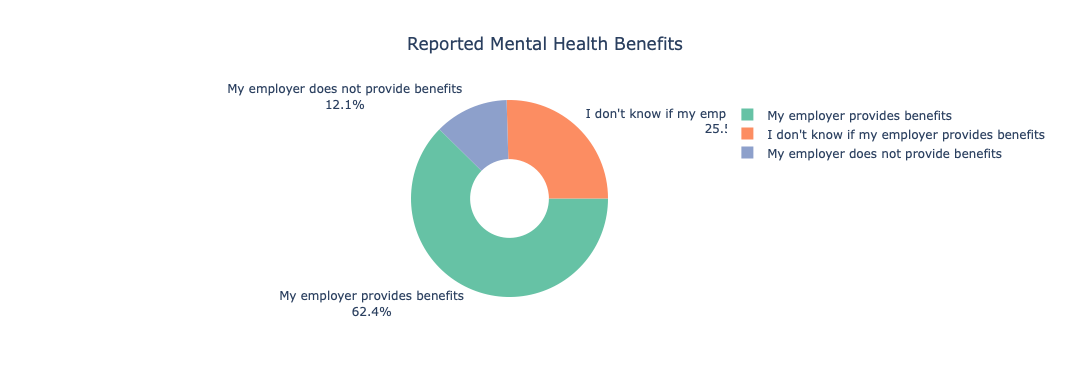

In [5]:
# Benefit counts
benefit_counts = benefits_analysis["benefits"].value_counts(dropna=True)

fig = px.pie(
    values=benefit_counts.values,
    names=benefit_counts.index,
    title="Reported Mental Health Benefits",
    hole=0.4,
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_traces(
    textposition="outside",
    textinfo="percent+label",
    rotation=90
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5
)

fig.show()

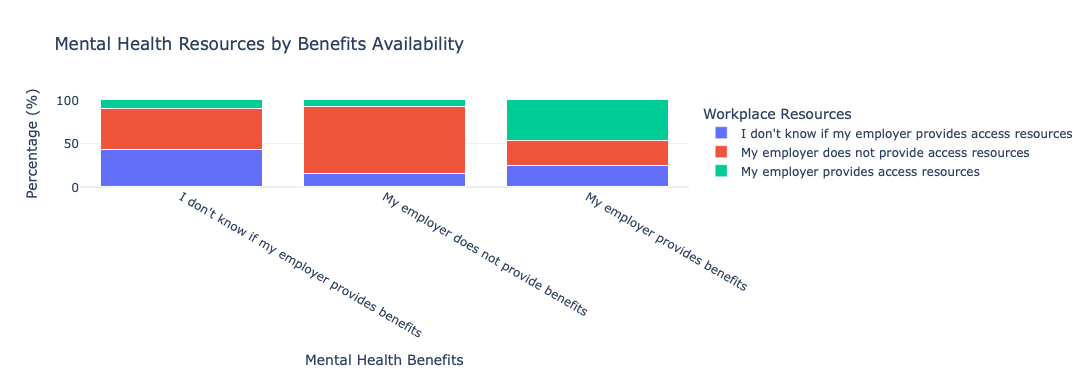

In [53]:
# Benefits x Workplace resources
h1_table = pd.crosstab(
    benefits_analysis["benefits"],
    benefits_analysis["workplace_resources"],
    normalize="index"
) * 100

# Convert the crosstab index into a regular column
h1_plot = h1_table.reset_index()

# Reshape the table for Plotly
h1_plot = h1_plot.melt(
    id_vars="benefits",
    var_name="workplace_resources",
    value_name="percentage"
)

fig = px.bar(
    h1_plot,
    x="benefits",
    y="percentage",
    color="workplace_resources",
    barmode="stack",
    template="plotly_white",
    title="Mental Health Resources by Benefits Availability",
    labels={
        "benefits": "Benefits",
        "percentage": "Percentage",
        "workplace_resources": "Workplace Resources"
    }
)

fig.update_layout(
    yaxis_title="Percentage (%)",
    xaxis_title="Mental Health Benefits",
    yaxis=dict(range=[0, 100])
)

fig.show()

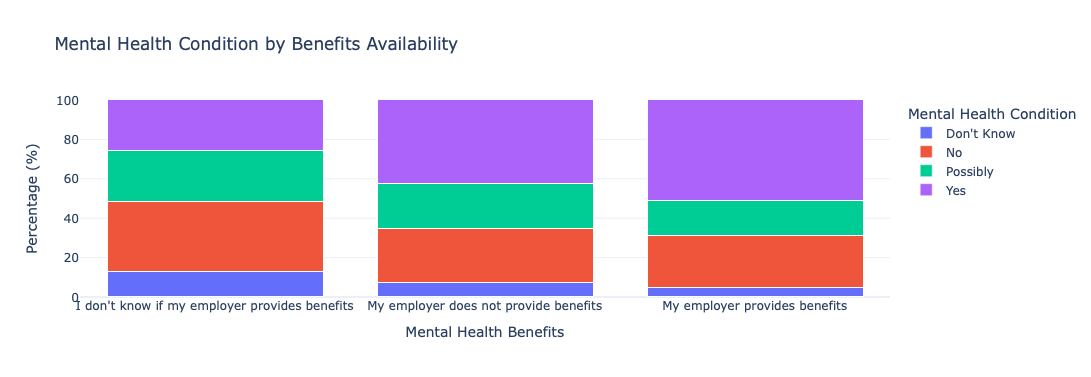

In [8]:
# Benefits x Mental Health
benefits_mh_table = pd.crosstab(
    benefits_analysis["benefits"], 
    benefits_analysis["mental_health"],
    normalize="index"
) * 100

# Convert the crosstab index into a regular column
bxmh_plot = benefits_mh_table.reset_index()

# Reshape the table for Plotly
bxmh_plot = bxmh_plot.melt(
    id_vars="benefits",
    var_name="mental_health",
    value_name="percentage"
)

fig = px.bar(
    bxmh_plot,
    x="benefits",
    y="percentage",
    color="mental_health",
    barmode="stack",
    template="plotly_white",
    title="Mental Health Condition by Benefits Availability",
    labels={
        "benefits": "Benefits",
        "percentage": "Percentage",
        "mental_health": "Mental Health Condition"
    }
)

fig.update_layout(
    yaxis_title="Percentage (%)",
    xaxis_title="Mental Health Benefits",
    yaxis=dict(range=[0, 100])
)

fig.show()

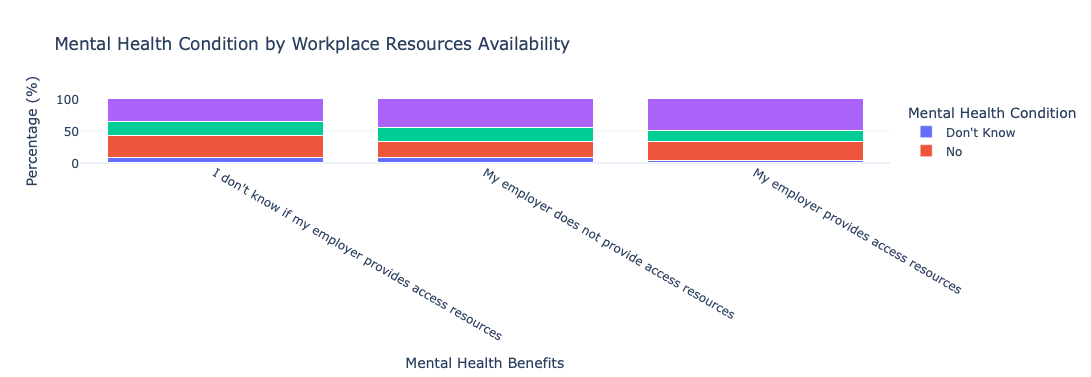

In [9]:
# Workplace Resources × Mental Health
workplace_resources_mh_table = pd.crosstab(
    benefits_analysis["workplace_resources"], 
    benefits_analysis["mental_health"],
    normalize="index"
) * 100

# Convert the crosstab index into a regular column
wrxmh_plot = workplace_resources_mh_table.reset_index()

# Reshape the table for Plotly
wrxmh_plot = wrxmh_plot.melt(
    id_vars="workplace_resources",
    var_name="mental_health",
    value_name="percentage"
)

fig = px.bar(
    wrxmh_plot,
    x="workplace_resources",
    y="percentage",
    color="mental_health",
    barmode="stack",
    template="plotly_white",
    title="Mental Health Condition by Workplace Resources Availability",
    labels={
        "workplace_resources": "Workplace Resources",
        "percentage": "Percentage",
        "mental_health": "Mental Health Condition"
    }
)

fig.update_layout(
    yaxis_title="Percentage (%)",
    xaxis_title="Mental Health Benefits",
    yaxis=dict(range=[0, 100])
)

fig.show()


# H2: Significant proportion of employees do not know whether their employer provides mental health benefits.

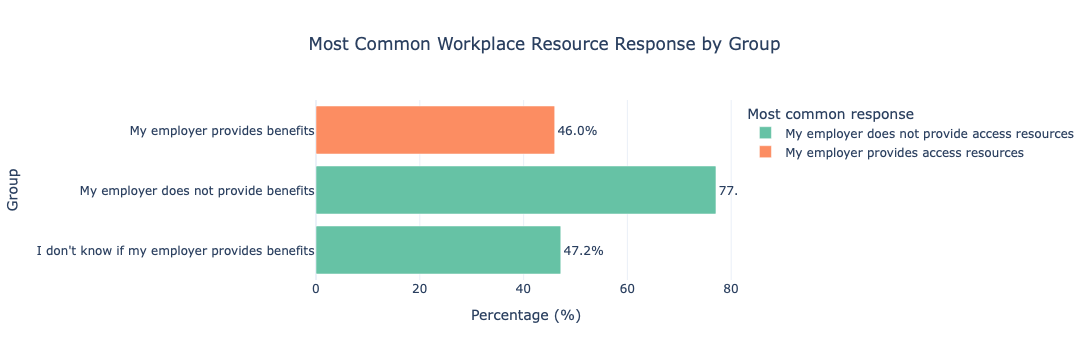

In [58]:
# Get the workplace resource with the highest percentage in each row
highest_resources = h1_table.idxmax(axis=1)
highest_percentages = h1_table.max(axis=1)

summary = pd.DataFrame({
    "Most common Response": highest_resources,
    "Percentage": highest_percentages.round(2)
})

fig = px.bar(
    summary.reset_index(),
    x="Percentage",
    y=summary.index.name or "index",
    color="Most common Response",
    text="Percentage",
    orientation="h",
    title="Most Common Workplace Resource Response by Group",
    labels={
        "Percentage": "Percentage (%)",
        "Most common Response": "Most common response"
    },
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_traces(
    texttemplate="%{text:.1f}%",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis_title="Percentage (%)",
    yaxis_title="Group",
    showlegend=True
)

fig.show()

Among respondents in the "benefits"/"Yes" category group, "workplace_resource"/"Yes" is the most common, with a percentage of 45.98. This means that most of the respondents that report having mental health benefits, report that the employer provides informational and educational resources to access those resources. However, "workplace_resources" / "No" and "I don't know" respondents, account for the majority of this group, with the percentages of 29.23 and 24.78, suggesting that most of the workers that report having mental benefits, don't have the resources to access it.
The "benefits"/"No" group most common response to "workplace_resources" is "No", suggesting that their workplace does not provide benefits and does not provide resources to access mental health education and information.
The "I don't Know" group shows very close percentages of respondents who state that they don't have or don't know about workplace resources.
These results suggest that, even if a company provides mental health benefits, the employees may not be aware of the availability of it.

# H3: Employees who have discussed mental health with colleagues are more likely to have discussed it with their employer.

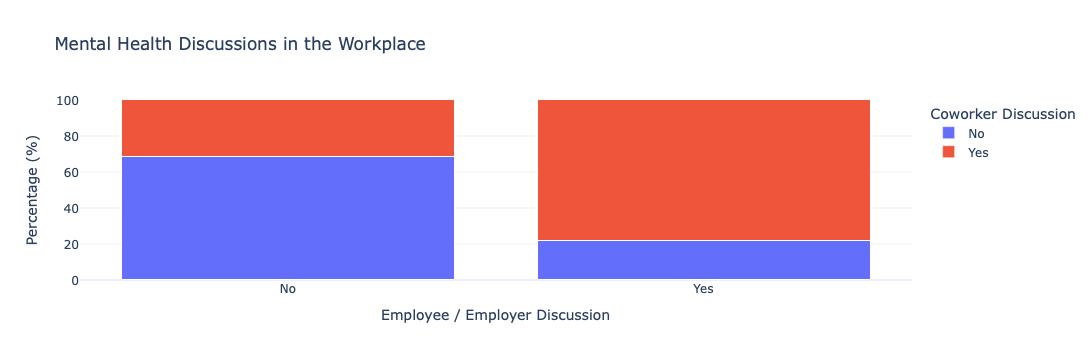

In [10]:
# Convert the crosstab index into a regular column
discussion_emp_cowor_table = pd.crosstab(
    benefits_analysis["mh_employer_discussion"],
    benefits_analysis["mh_coworker_discussion"],
    normalize="index"
) * 100

discussion_plot = discussion_emp_cowor_table.reset_index()

# Reshape the table for Plotly
discussion_plot = discussion_plot.melt(
    id_vars="mh_employer_discussion",
    var_name="mh_coworker_discussion",
    value_name="percentage"
)

fig = px.bar(
    discussion_plot,
    x="mh_employer_discussion",
    y="percentage",
    color="mh_coworker_discussion",
    barmode="stack",
    template="plotly_white",
    title="Mental Health Discussions in the Workplace",
    labels={
        "mh_employer_discussion": "Employer / Employee Discussion",
        "percentage": "Percentage",
        "mh_coworker_discussion": "Coworker Discussion"
    }
)

fig.update_layout(
    yaxis_title="Percentage (%)",
    xaxis_title="Employee / Employer Discussion",
    yaxis=dict(range=[0, 100])
)

fig.show()

Among respondents in the “coworker discussion: No” category, 68.8% also reported that they did not discuss mental health with their employer. This suggests that most respondents who do not discuss mental health with their coworkers also avoid discussing it with their employer.

In contrast, among respondents who reported discussing mental health with their coworkers, 78.15% also reported discussing it with their employer.

These results suggest that, in workplaces where employees discuss mental health with their coworkers, they may also be more likely to discuss it with their employer. However, this indicates an association rather than a causal relationship. 

# H4: Organisations highlight the availability of mental health resources more often than they communicate how employees can access them.

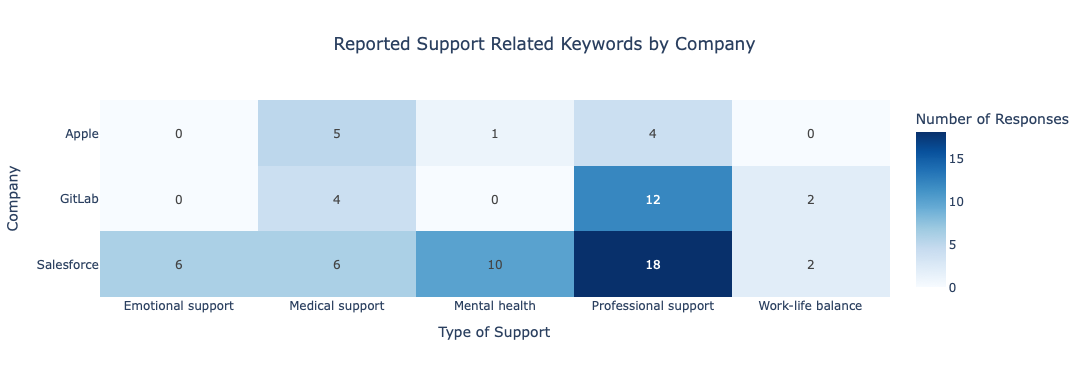

In [14]:
# Creating a heat map with the keyword dataset
support_counts = pd.DataFrame({
    "Emotional support": [0, 0, 6],
    "Medical support": [5, 4, 6],
    "Mental health": [1, 0, 10],
    "Professional support": [4, 12, 18],
    "Work-life balance": [0, 2, 2]
}, index=["Apple", "GitLab", "Salesforce"])

support_counts.index.name = "Company"

fig = px.imshow(
    support_counts,
    text_auto=".0f",
    color_continuous_scale="Blues",
    aspect="auto",
    labels={
        "x": "Type of Support",
        "y": "Company",
        "color": "Number of Responses"
    },
    title="Reported Support Related Keywords by Company"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5
)

fig.show()